# Milestone 2 - Data Cleaning and Preparation
**Martik Farm Enterprises (synthetic data calibrated on the real Java House price list)**

This notebook runs the whole cleaning pipeline (`src/clean_data.py`) from the raw CSVs in `data/` and shows, for every step,
what was wrong, how many rows were affected, and the state afterwards. Raw files are never edited, so the notebook can be re-run at any time.

| Step | What it handles |
|---|---|
| 1 Types | text dates -> datetime, IDs trimmed, numerics checked |
| 2 Duplicates | double-entered order lines |
| 3 Consistency | payment-method spellings |
| 4 Missing values | blank delivery area / channel, blanks that mean "none" |
| 5 Outliers | decimal-slip prices (vs monthly price list), extreme quantities |
| 6 Reconciliation | line totals vs order subtotals, payments, orphan keys |
| 7 Features | sales fact table, order features, RFM, monthly churn panel, weekly sales |
| 8 Checks | hard assertions: the pipeline fails if the cleaned data breaks a rule |

In [1]:
import sys, warnings
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
import clean_data as cd
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 80); pd.set_option("display.max_rows", 100)

tables, report = cd.main(ROOT / "data", ROOT / "data_clean", ROOT / "reports")   # raw -> clean
print("Pipeline finished. Clean files written to data_clean/, report to reports/")

Pipeline finished. Clean files written to data_clean/, report to reports/


## 1. Before / after summary: what each step fixed

In [2]:
fixed = report[report.step.str[0].isin(list("2345678")) ].copy()
fixed = fixed[fixed.before.astype(str) != fixed.after.astype(str)]       # only checks where something changed
fixed[["step", "table", "check", "before", "after", "action"]].reset_index(drop=True)

,step,table,check,before,after,action
0,2 duplicates,order_lines,exact duplicate rows (all columns identical),382,0,kept first occurrence of each row
1,2 duplicates,order_lines,duplicated line_id,382,0,resolved by the step above
2,2 duplicates,order_lines,row count,127736,127354,removed 382 double-entered lines
3,3 consistency,payments,distinct spellings of payment method,17,4,"mapped to M-Pesa / Bank Transfer / Cheque / Cash (617 rows rewritten, 0 unma..."
4,4 missing,orders,delivery_area missing,8460,0,"8,302 were walk-in sales (no delivery: labelled 'In-shop (walk-in)'); 158 ac..."
5,4 missing,orders,order_channel missing,447,0,170 walk-in sales set to 'Walk-in'; the rest labelled 'Unknown' (not guessed)
6,4 missing,order_lines,promo_id blank,122688,0,blank means no promotion -> 'NO_PROMO'
7,4 missing,order_lines,reject_reason blank,124864,0,blank means nothing rejected -> 'None' (0 rows had a rejection with no reason)
8,5 outliers,order_lines,unit price > 3x the monthly list price (decimal-slip keying errors),82,0,82 corrected by dividing price and line total by 10 (flag: price_corrected=1)
9,5 outliers,order_lines,unit price outside 0.8x-1.4x of monthly list price,82,0,all remaining prices are inside the expected band


The full log (including the checks that found nothing to fix) is in `reports/cleaning_report.md`.

In [3]:
report[["step", "table", "check", "before", "after"]]

,step,table,check,before,after
0,0 load,all,raw rows (orders / order_lines / payments),"20,852 / 127,736 / 20,236",-
1,1 types,orders,order_date: text -> datetime (values that fail to parse),0,0
2,1 types,orders,invoice_due_date: text -> datetime (values that fail to parse),0,0
3,1 types,payments,payment_date: text -> datetime (values that fail to parse),0,0
4,1 types,calendar,date: text -> datetime (values that fail to parse),0,0
5,1 types,promotions,start_date: text -> datetime (values that fail to parse),0,0
6,1 types,promotions,end_date: text -> datetime (values that fail to parse),0,0
7,1 types,customers,first_order_date: text -> datetime (values that fail to parse),0,0
8,1 types,all,tables loaded,9,9
9,2 duplicates,order_lines,exact duplicate rows (all columns identical),382,0


## 2. Evidence, step by step

### Duplicates: double-entered order lines

In [4]:
raw_lines = pd.read_csv(ROOT / "data" / "order_lines.csv", low_memory=False)
dup_ids = raw_lines[raw_lines.line_id.duplicated(keep=False)].sort_values("line_id")
print(f"raw rows: {len(raw_lines):,} | duplicated line_ids: {raw_lines.line_id.duplicated().sum():,} | clean rows: {len(tables['order_lines']):,}")
dup_ids.head(6)[["line_id", "order_id", "product_id", "quantity_ordered", "unit_price_kes", "line_total_kes"]]

raw rows: 127,736 | duplicated line_ids: 382 | clean rows: 127,354


,line_id,order_id,product_id,quantity_ordered,unit_price_kes,line_total_kes
317,L0000318,ORD000049,31,9.5,90.0,855.0
318,L0000318,ORD000049,31,9.5,90.0,855.0
633,L0000633,ORD000102,7,10.0,70.0,700.0
634,L0000633,ORD000102,7,10.0,70.0,700.0
653,L0000652,ORD000105,18,5.5,45.0,247.5
654,L0000652,ORD000105,18,5.5,45.0,247.5


### Consistency: payment-method spellings

In [5]:
raw_pay = pd.read_csv(ROOT / "data" / "payments.csv")
before = raw_pay.method.value_counts().rename("rows_before")
after = tables["payments"].method.value_counts().rename("rows_after")
print(f"distinct spellings: {raw_pay.method.nunique()} -> {tables['payments'].method.nunique()}")
after.to_frame()

distinct spellings: 17 -> 4


,rows_after
method,
M-Pesa,10426
Bank Transfer,5731
Cash,2707
Cheque,1372


In [6]:
before.to_frame()

,rows_before
method,
M-Pesa,10099
Bank Transfer,5566
Cash,2622
Cheque,1332
mpesa,95
Mpesa,81
M pesa,76
M-PESA,75
cash,51


### Missing values

In [7]:
raw_orders = pd.read_csv(ROOT / "data" / "orders.csv")
cols = ["delivery_area", "order_channel"]
pd.DataFrame({"missing_before": raw_orders[cols].isna().sum(), "missing_after": tables["orders"][cols].isna().sum()})

,missing_before,missing_after
delivery_area,8460,0
order_channel,447,0


In [8]:
walk = tables["orders"].is_account.eq(0)
print("Walk-in orders have no delivery address by design, so they were labelled, not imputed:")
print(tables["orders"].loc[walk, "delivery_area"].value_counts().to_string())
print("\nAccount orders: missing delivery area recovered from the customer record. Example:")
tables["orders"].loc[raw_orders.delivery_area.isna() & ~walk, ["order_id", "customer_id", "delivery_area"]].head(5)

Walk-in orders have no delivery address by design, so they were labelled, not imputed:
delivery_area
In-shop (walk-in)    8302

Account orders: missing delivery area recovered from the customer record. Example:


,order_id,customer_id,delivery_area
15,ORD000016,C151,Embakasi
54,ORD000055,C163,South B/C
203,ORD000204,C123,Langata
211,ORD000212,C162,Westlands
311,ORD000312,C121,Kilimani


### Outliers: decimal-slip prices

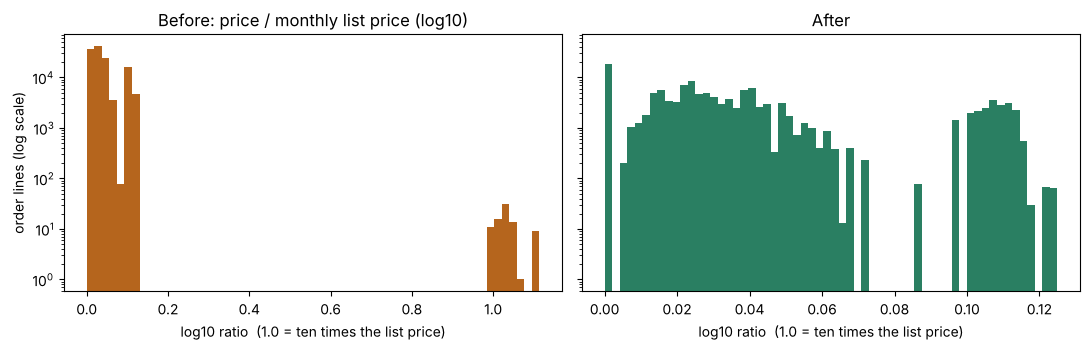

82 prices corrected. Examples (raw price vs corrected):


,line_id,product_id,unit_price_kes_clean,unit_price_kes_raw
0,L0002207,35,90.0,900.0
1,L0007073,3,135.0,1350.0
2,L0008135,25,80.0,800.0
3,L0009666,37,100.0,1000.0
4,L0010161,25,100.0,1000.0


In [9]:
L = raw_lines.drop_duplicates().copy()
o = tables["orders"].set_index("order_id")
pl = tables["price_list_monthly"]
L["month"] = L.order_id.map(o.order_date.dt.strftime("%Y-%m"))
L = L.merge(pl.rename(columns={"month": "month", "list_price_kes": "list"})[["month", "product_id", "list"]], on=["month", "product_id"], how="left")
L["ratio_raw"] = L.unit_price_kes / L.list
C = tables["order_lines"].merge(L[["line_id", "list"]], on="line_id", how="left")
C["ratio_clean"] = C.unit_price_kes / C.list
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
ax[0].hist(np.log10(L.ratio_raw), bins=60, color="#b5651d"); ax[0].set_title("Before: price / monthly list price (log10)")
ax[1].hist(np.log10(C.ratio_clean), bins=60, color="#2a7f62"); ax[1].set_title("After")
for a in ax: a.set_xlabel("log10 ratio  (1.0 = ten times the list price)"); a.set_yscale("log")
ax[0].set_ylabel("order lines (log scale)"); plt.tight_layout(); plt.show()
fixed_rows = tables["order_lines"][tables["order_lines"].price_corrected == 1]
print(f"{len(fixed_rows)} prices corrected. Examples (raw price vs corrected):")
ex = fixed_rows.head(5)[["line_id", "product_id", "unit_price_kes"]].merge(raw_lines[["line_id", "unit_price_kes"]].drop_duplicates("line_id"), on="line_id", suffixes=("_clean", "_raw"))
ex

In [10]:
q = tables["order_lines"]
print(f"Quantity outliers flagged (kept, not deleted): {int(q.is_qty_outlier.sum())} of {len(q):,} lines")
q[q.is_qty_outlier == 1].merge(tables["products"][["product_id", "product_name"]], on="product_id")[["line_id", "product_name", "quantity_ordered"]].sort_values("quantity_ordered", ascending=False).head(5)

Quantity outliers flagged (kept, not deleted): 388 of 127,354 lines


,line_id,product_name,quantity_ordered
76,L0014176,Wedge Potatoes,58.5
262,L0076803,Potatoes White,57.0
168,L0063646,Plantain Horn,49.0
252,L0075417,White Onion (Peeled),49.0
176,L0064762,Wedge Potatoes,42.5


### Reconciliation: do the numbers add up?

In [11]:
rep = report[report.step == "6 reconcile"][["table", "check", "before", "after"]]
rep

,table,check,before,after
31,orders vs order_lines,orders whose line totals do not add up to the subtotal (>1 KES),450,0
32,order_lines,line_total != billed qty x price x (1 - discount),0,0
33,orders,order_total != subtotal + delivery fee,0,0
34,orders,invoice_due_date != order_date + payment terms,0,0
35,payments,payment amount != order total,0,0
36,payments,payment dated before the order,0,0
37,payments,payments on orders not marked Paid,0,0
38,orders,orders marked Paid with no payment record,0,0
39,lines -> orders,orphan keys (no matching parent),0,0
40,lines -> products,orphan keys (no matching parent),0,0


In [12]:
f = pd.read_csv(ROOT / "data_clean" / "sales_fact.csv")
print(f"Revenue in the clean fact table : KES {f.line_total_kes.sum():,.2f}")
print(f"Sum of order subtotals          : KES {tables['orders'].subtotal_kes.sum():,.2f}")
raw_sum = raw_lines.line_total_kes.sum()
print(f"Raw order lines (before fixes)  : KES {raw_sum:,.2f}  -> overstated by KES {raw_sum - f.line_total_kes.sum():,.2f}")

Revenue in the clean fact table : KES 75,884,399.51
Sum of order subtotals          : KES 75,884,399.51
Raw order lines (before fixes)  : KES 76,556,102.97  -> overstated by KES 671,703.46


## 3. Features built

In [13]:
f.shape, list(f.columns)

((127354, 41),
 ['line_id',
  'order_id',
  'product_id',
  'store_id',
  'quantity_ordered',
  'quantity_rejected',
  'reject_reason',
  'unit_price_kes',
  'discount_pct',
  'promo_id',
  'unit_cost_kes',
  'line_total_kes',
  'price_corrected',
  'is_qty_outlier',
  'billed_qty',
  'gross_revenue_kes',
  'discount_kes',
  'cost_kes',
  'gross_margin_kes',
  'margin_pct',
  'is_promo',
  'rejected_value_kes',
  'order_date',
  'customer_id',
  'segment',
  'is_account',
  'county',
  'delivery_area',
  'order_channel',
  'payment_terms_days',
  'payment_status',
  'week_start',
  'day_of_week',
  'is_public_holiday',
  'business_season',
  'product_name',
  'category',
  'unit',
  'store_name',
  'store_county',
  'year_month'])

In [14]:
f.head(3).T

,0,1,2
line_id,L0000001,L0000002,L0000003
order_id,ORD000001,ORD000001,ORD000001
product_id,1,5,8
store_id,S01,S02,S02
quantity_ordered,17.5,13.0,16.0
quantity_rejected,0.0,0.0,0.0
reject_reason,NaN,NaN,NaN
unit_price_kes,90.0,65.0,290.0
discount_pct,0,0,0
promo_id,NO_PROMO,NO_PROMO,NO_PROMO


**Customer RFM** (snapshot 30 Sep 2026): recency, frequency, monetary, 1-5 scores and segments.

In [15]:
r = tables["customer_rfm"]
display(r.rfm_segment.value_counts().to_frame("accounts"))
r.sort_values("monetary_kes", ascending=False).head(5)[["customer_name", "segment", "recency_days", "frequency", "monetary_kes", "R", "F", "M", "rfm_segment"]]

,accounts
rfm_segment,
Champions,16
Lost / low value,16
Loyal,14
At risk,12
Needs attention,7
Recent,5


,customer_name,segment,recency_days,frequency,monetary_kes,R,F,M,rfm_segment
0,Java House,Coffee Chain,0,583,11891049.00,4,5,5,Champions
1,Norfolk Hotel,Hotel/Lodge,0,505,6871026.94,4,5,5,Champions
36,Hotel 033,Hotel/Lodge,119,541,6012476.95,2,5,5,At risk
40,Hotel 037,Hotel/Lodge,0,466,4258120.20,5,5,5,Champions
2,The Chef Restaurant,Restaurant,0,403,4173575.97,4,5,5,Champions


**Churn panel**: one row per active account per month-end snapshot (Jan 2025 - Jul 2026). Features use only data up to the snapshot;
the label `churned_next_60d` = no order in the following 60 days. Payments are counted only if made on or before the snapshot (no leakage).

In [16]:
cp = tables["churn_panel"]
print(f"{len(cp):,} rows | {cp.snapshot_date.nunique()} snapshots | churn rate {cp.churned_next_60d.mean():.1%} ({int(cp.churned_next_60d.sum())} positives)")
cp.groupby("segment").churned_next_60d.agg(rows="size", churned="sum")

995 rows | 19 snapshots | churn rate 5.4% (54 positives)


,rows,churned
segment,,
Cafe/Bakery,181,6
Caterer,132,12
Coffee Chain,19,0
Fast Food,86,6
Grocer/Supermarket,83,6
Hotel/Lodge,80,6
Restaurant,305,12
School/Daycare,109,6


> **Known caveat:** a few positives are schools going quiet in the December holidays, not real churn (see Riara / other schools at the
> 31 Oct 2025 snapshot). Handle with the `is_school` feature or by excluding the holiday window when you build the model.

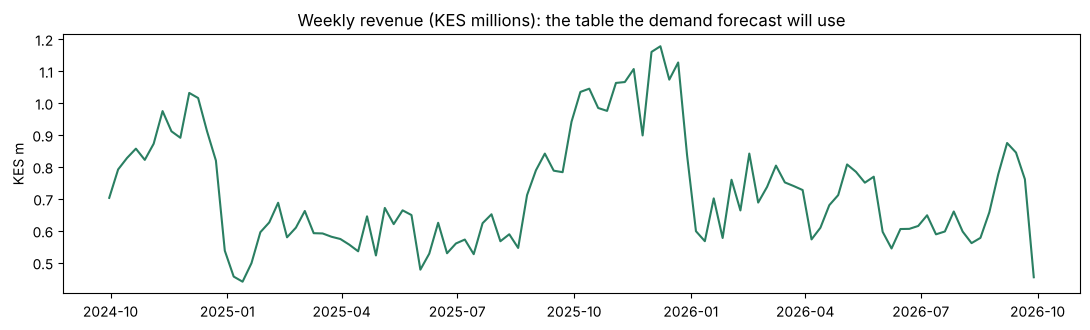

,week_start,revenue_kes,billed_qty,order_lines,category,orders,holiday_days,season
0,2024-09-30,702408.5,6106.5,1096,ALL,191,0,Peak
1,2024-10-07,791423.5,6773.0,1131,ALL,165,1,Peak
2,2024-10-14,827261.5,7195.0,1237,ALL,193,0,Peak
3,2024-10-21,856532.5,7186.0,1263,ALL,210,1,Peak
4,2024-10-28,821381.5,7021.5,1242,ALL,207,0,Peak


In [17]:
w = tables["weekly_sales"]
tot = w[w.category == "ALL"]
fig, ax = plt.subplots(figsize=(11, 3.4)); ax.plot(pd.to_datetime(tot.week_start), tot.revenue_kes / 1e6, color="#2a7f62")
ax.set_title("Weekly revenue (KES millions): the table the demand forecast will use"); ax.set_ylabel("KES m"); plt.tight_layout(); plt.show()
tot.head()

## 4. Final checks
The pipeline stops with an error if any of these fail. All passed:

In [18]:
print(report[report.step == "8 checks"].action.iloc[0].replace("; ", "\n"))

line_id unique
order_id unique
payment_id unique
orders reconcile to lines
line totals recompute
payment methods standardised
no nulls in order_channel/delivery_area
all lines have a known order
dates inside the data window
no negative billed quantity
churn panel has both classes


## How to re-run
```bash
pip install pandas numpy matplotlib
python src/clean_data.py            # raw data/ -> data_clean/ + reports/cleaning_report.md
```
Running it twice produces byte-identical output (checked by file hash).